In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
dataset_dir = r"D:\myfiles\DHANLAXMI\SkillCraft-ML-Internship\SCT_ML_4"

train_path = os.path.join(dataset_dir, "sign_mnist_train.csv")
test_path = os.path.join(dataset_dir, "sign_mnist_test.csv")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

display(train_df.head())

Training dataset shape: (27455, 785)
Testing dataset shape: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [4]:
X_train = train_df.drop("label", axis=1).values
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values
y_test = test_df["label"].values

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (27455, 784)
Training labels: (27455,)
Testing images: (7172, 784)
Testing labels: (7172,)


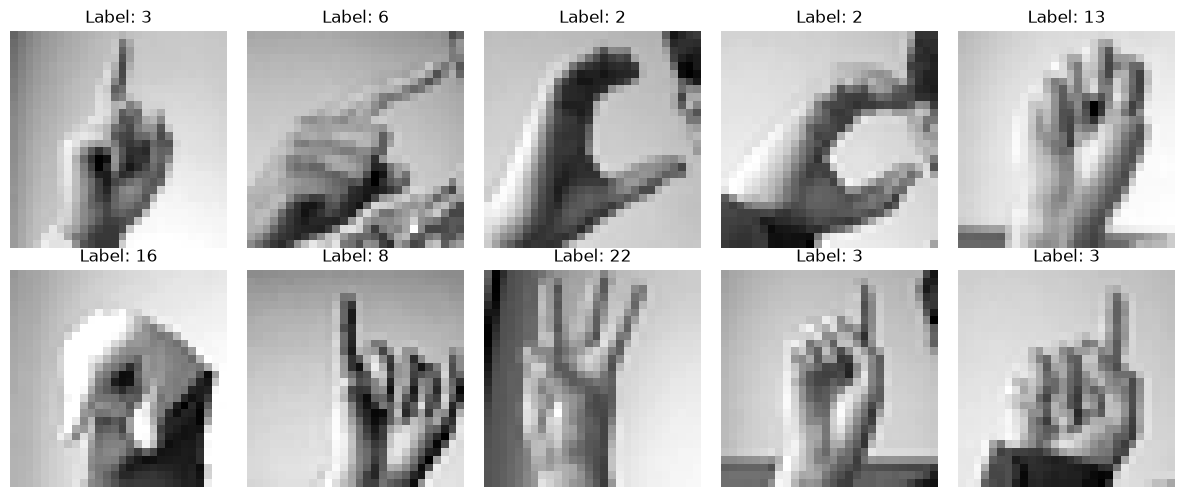

In [5]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    image = X_train[i].reshape(28, 28)
    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Pixel normalization completed!")
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Pixel normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [7]:
# Reduce dimensions using PCA
pca = PCA(n_components=100, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("PCA completed!")
print("Original features:", X_train.shape[1])
print("Reduced features:", X_train_pca.shape[1])
print(
    "Variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA completed!
Original features: 784
Reduced features: 100
Variance retained: 94.23 %


In [8]:
# Train the Support Vector Machine model
model = SVC(kernel="rbf", C=5, gamma="scale")

model.fit(X_train_pca, y_train)

print("Hand Gesture Recognition model trained successfully!")

Hand Gesture Recognition model trained successfully!


In [9]:
y_pred = model.predict(X_test_pca)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy: 85.96%

Classification Report:

              precision    recall  f1-score   support

           0       0.92      1.00      0.96       331
           1       1.00      1.00      1.00       432
           2       0.85      0.99      0.92       310
           3       0.97      1.00      0.98       245
           4       0.96      1.00      0.98       498
           5       0.70      0.83      0.76       247
           6       0.93      0.93      0.93       348
           7       0.99      0.94      0.96       436
           8       0.82      0.87      0.84       288
          10       0.82      0.70      0.75       331
          11       0.90      0.93      0.92       209
          12       0.86      0.75      0.80       394
          13       0.90      0.69      0.78       291
          14       0.99      0.85      0.91       246
          15       1.00      1.00      1.00       347
          16       0.99      1.00      1.00       164
          17       0.36      0.59 

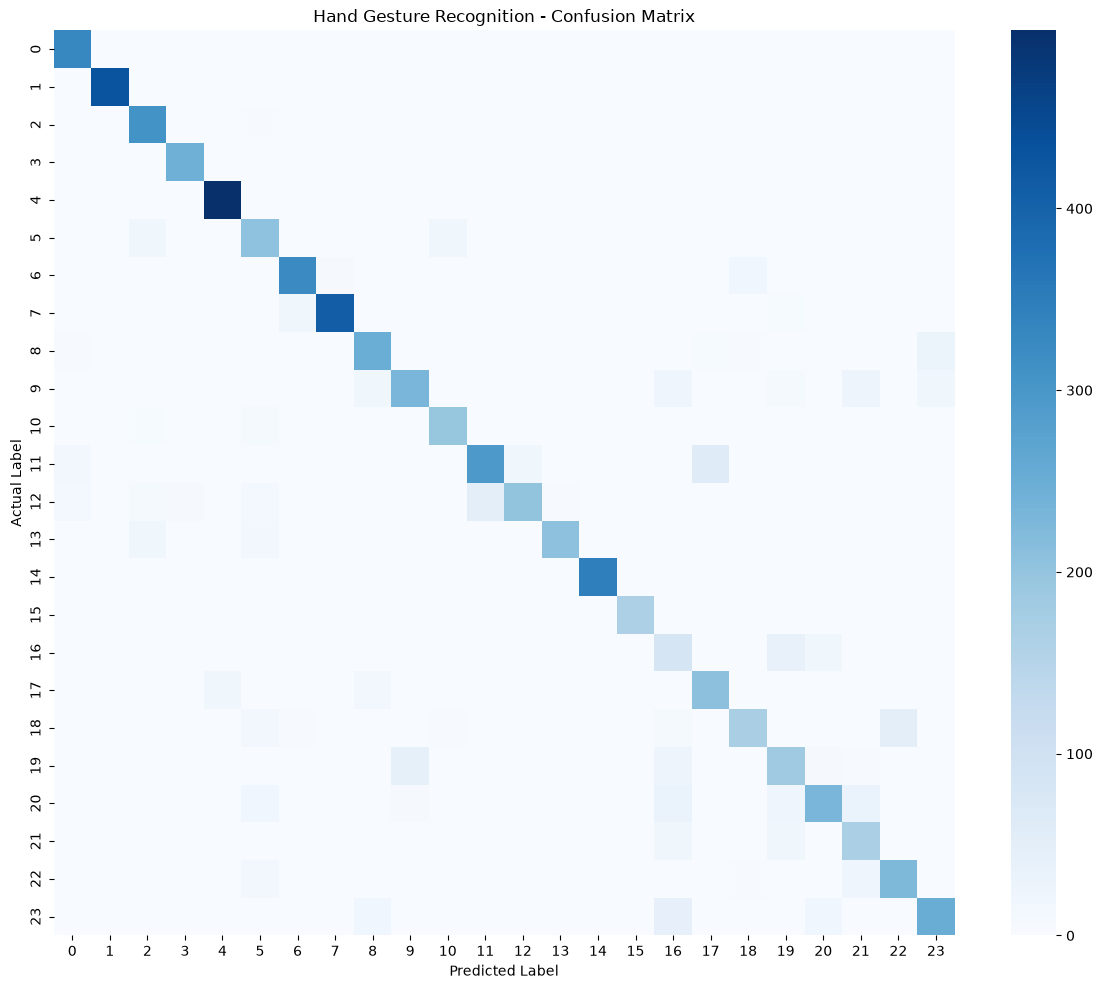

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", annot=False)
plt.title("Hand Gesture Recognition - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

os.makedirs("results", exist_ok=True)
plt.savefig("results/confusion_matrix.png", dpi=300)
plt.show()

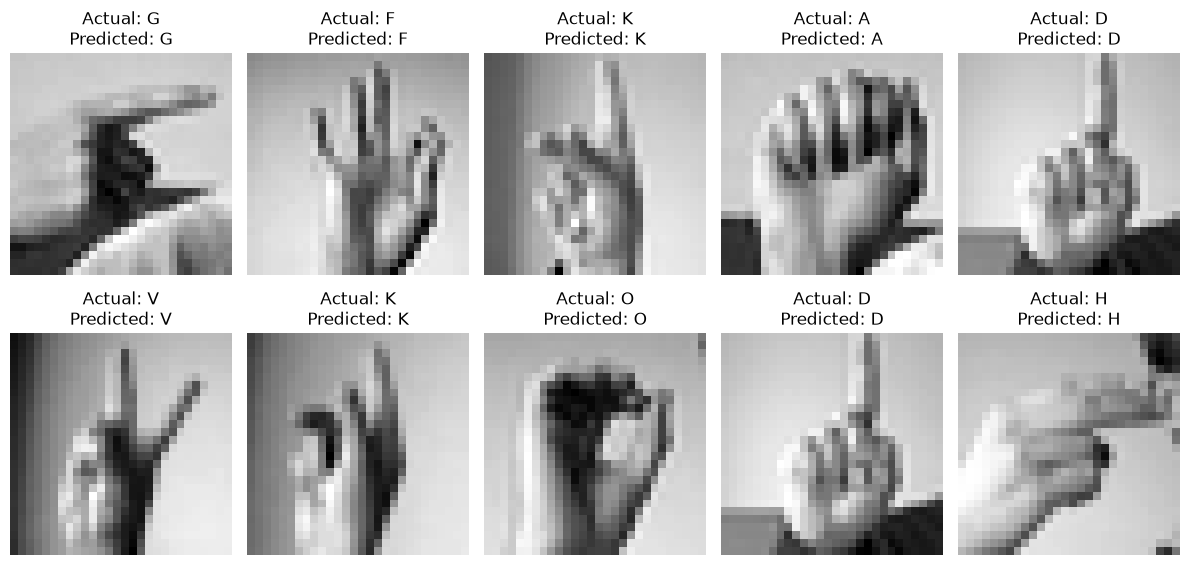

In [11]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(28, 28)
    actual = int(y_test[i])
    predicted = int(y_pred[i])

    plt.imshow(image, cmap="gray")
    plt.title(f"Actual: {chr(actual + 65)}\nPredicted: {chr(predicted + 65)}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("results/sample_predictions.png", dpi=300)
plt.show()

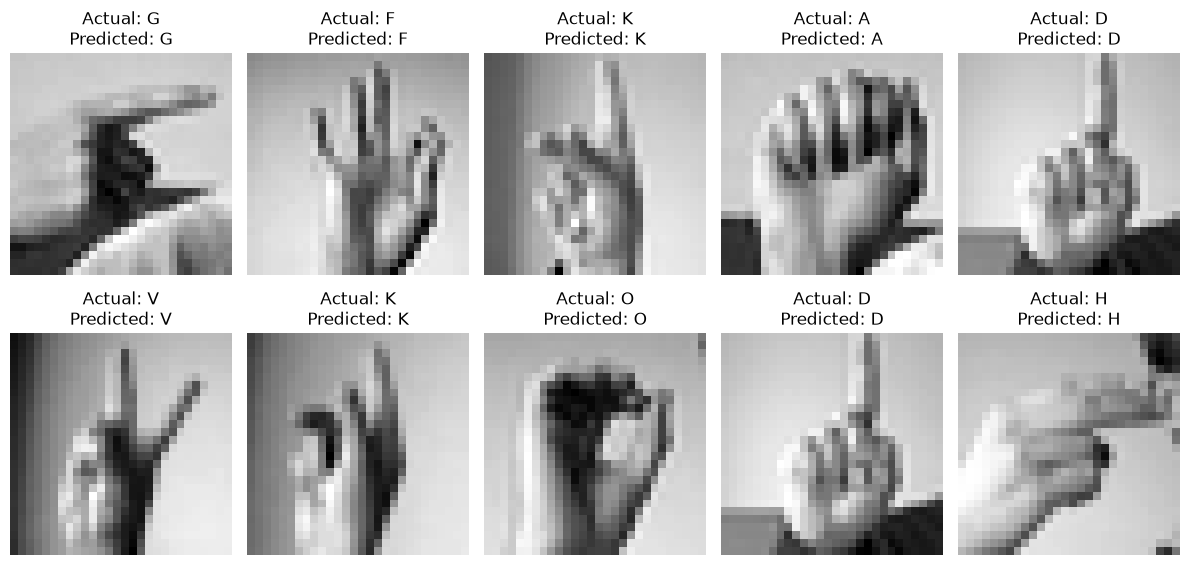

In [12]:
# Correct mapping for Sign Language MNIST
label_to_letter = {
    i: letter
    for i, letter in enumerate("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
    if letter not in ["J", "Z"]
}

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")

    actual_letter = label_to_letter[int(y_test[i])]
    predicted_letter = label_to_letter[int(y_pred[i])]

    plt.title(
        f"Actual: {actual_letter}\nPredicted: {predicted_letter}"
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig("results/sample_predictions.png", dpi=300)
plt.show()

In [13]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(model, "artifacts/hand_gesture_svm.pkl")
joblib.dump(pca, "artifacts/hand_gesture_pca.pkl")

print("Model and PCA saved successfully!")

Model and PCA saved successfully!


In [14]:
with open("results/model_results.txt", "w") as f:
    f.write("Hand Gesture Recognition - Task 4\n")
    f.write(f"Test Accuracy: {accuracy * 100:.2f}%\n")
    f.write(f"Training images: {len(X_train)}\n")
    f.write(f"Testing images: {len(X_test)}\n")
    f.write("Algorithm: Support Vector Machine (SVM)\n")
    f.write("Dimensionality Reduction: PCA\n")

print("Results saved successfully!")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Results saved successfully!
Test Accuracy: 85.96%
